In [3]:

!pip install -q datasets

from datasets import load_dataset

print("Loading PlantVillage dataset...")

plant_dataset = load_dataset("mohanty/PlantVillage", "default")

print("\nDataset loaded successfully!")
print(plant_dataset)

# Inspect one example from the training split
print("\nFirst training example:")
print(plant_dataset["train"][0])

# Check the available columns
print("\nDataset columns:")
print(plant_dataset["train"].column_names)


Loading PlantVillage dataset...


README.md:   0%|          | 0.00/6.47k [00:00<?, ?B/s]

color_train.txt:   0%|          | 0.00/4.15M [00:00<?, ?B/s]

grayscale_train.txt:   0%|          | 0.00/4.28M [00:00<?, ?B/s]

segmented_train.txt:   0%|          | 0.00/4.86M [00:00<?, ?B/s]

color_test.txt:   0%|          | 0.00/1.02M [00:00<?, ?B/s]

grayscale_test.txt:   0%|          | 0.00/1.10M [00:00<?, ?B/s]

segmented_test.txt:   0%|          | 0.00/1.28M [00:00<?, ?B/s]

Generating train split: 0 examples [00:00, ? examples/s]

Generating test split: 0 examples [00:00, ? examples/s]


Dataset loaded successfully!
DatasetDict({
    train: Dataset({
        features: ['text'],
        num_rows: 129783
    })
    test: Dataset({
        features: ['text'],
        num_rows: 33133
    })
})

First training example:
{'text': 'raw/color/Raspberry___healthy/a37f34f7-022d-461a-8a3d-95f5cd774e35___Mary_HL 9155.JPG'}

Dataset columns:
['text']


2. Load the correct plant village dataset.

Loading PlantVillage images...


README.md:   0%|          | 0.00/549 [00:00<?, ?B/s]

data/train-00000-of-00002.parquet: reconstructing file:   0%|          |  0.00B /  402MB            

data/train-00000-of-00002.parquet: downloading bytes:           |  0.00B            

data/train-00001-of-00002.parquet: reconstructing file:   0%|          |  0.00B /  453MB            

data/train-00001-of-00002.parquet: downloading bytes:           |  0.00B            

Generating train split:   0%|          | 0/54304 [00:00<?, ? examples/s]


Dataset loaded!
Dataset({
    features: ['image', 'class_label', 'class_idx', 'host', 'disease', 'split', 'leaf_id', 'leaf_grouped'],
    num_rows: 54304
})

Available columns:
['image', 'class_label', 'class_idx', 'host', 'disease', 'split', 'leaf_id', 'leaf_grouped']

First example:
Class: Apple___Apple_scab
Split: test
Image type: <class 'PIL.JpegImagePlugin.JpegImageFile'>
Image size: (256, 256)


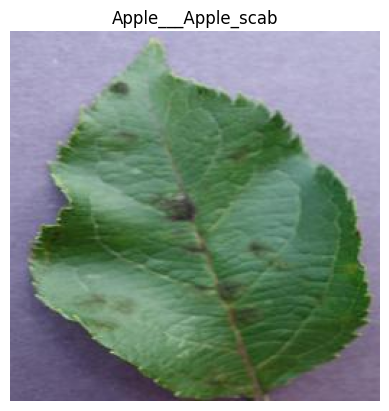

In [4]:


print("Loading PlantVillage images...")

plant_dataset = load_dataset(
    "geraldmc/plantvillage-full",
    revision="v0.1.0",
    split="train"
)

print("\nDataset loaded!")
print(plant_dataset)

print("\nAvailable columns:")
print(plant_dataset.column_names)

print("\nFirst example:")
example = plant_dataset[0]

print("Class:", example["class_label"])
print("Split:", example["split"])
print("Image type:", type(example["image"]))
print("Image size:", example["image"].size)

# Display the actual leaf photograph
import matplotlib.pyplot as plt

plt.imshow(example["image"])
plt.title(example["class_label"])
plt.axis("off")
plt.show()


######**SECTION 3: Check available classes**

In [5]:

# Section 3: Check the available classes

print("Number of classes:", len(set(plant_dataset["class_label"])))

print("\nAvailable classes:")

classes = sorted(set(plant_dataset["class_label"]))

for class_name in classes:
    print(class_name)


Number of classes: 38

Available classes:
Apple___Apple_scab
Apple___Black_rot
Apple___Cedar_apple_rust
Apple___healthy
Blueberry___healthy
Cherry_(including_sour)___Powdery_mildew
Cherry_(including_sour)___healthy
Corn_(maize)___Cercospora_leaf_spot Gray_leaf_spot
Corn_(maize)___Common_rust_
Corn_(maize)___Northern_Leaf_Blight
Corn_(maize)___healthy
Grape___Black_rot
Grape___Esca_(Black_Measles)
Grape___Leaf_blight_(Isariopsis_Leaf_Spot)
Grape___healthy
Orange___Haunglongbing_(Citrus_greening)
Peach___Bacterial_spot
Peach___healthy
Pepper,_bell___Bacterial_spot
Pepper,_bell___healthy
Potato___Early_blight
Potato___Late_blight
Potato___healthy
Raspberry___healthy
Soybean___healthy
Squash___Powdery_mildew
Strawberry___Leaf_scorch
Strawberry___healthy
Tomato___Bacterial_spot
Tomato___Early_blight
Tomato___Late_blight
Tomato___Leaf_Mold
Tomato___Septoria_leaf_spot
Tomato___Spider_mites Two-spotted_spider_mite
Tomato___Target_Spot
Tomato___Tomato_Yellow_Leaf_Curl_Virus
Tomato___Tomato_mosa

In [6]:

# Section 4: Count images in all 38 classes

from collections import Counter

class_counts = Counter(plant_dataset["class_label"])

print("Number of classes:", len(class_counts))
print("Total number of images:", len(plant_dataset))

print("\nNumber of images per class:\n")

for class_name, count in sorted(class_counts.items()):
    print(f"{class_name}: {count}")


Number of classes: 38
Total number of images: 54304

Number of images per class:

Apple___Apple_scab: 630
Apple___Black_rot: 621
Apple___Cedar_apple_rust: 275
Apple___healthy: 1645
Blueberry___healthy: 1502
Cherry_(including_sour)___Powdery_mildew: 1052
Cherry_(including_sour)___healthy: 854
Corn_(maize)___Cercospora_leaf_spot Gray_leaf_spot: 513
Corn_(maize)___Common_rust_: 1192
Corn_(maize)___Northern_Leaf_Blight: 985
Corn_(maize)___healthy: 1162
Grape___Black_rot: 1180
Grape___Esca_(Black_Measles): 1383
Grape___Leaf_blight_(Isariopsis_Leaf_Spot): 1076
Grape___healthy: 423
Orange___Haunglongbing_(Citrus_greening): 5507
Peach___Bacterial_spot: 2297
Peach___healthy: 360
Pepper,_bell___Bacterial_spot: 997
Pepper,_bell___healthy: 1477
Potato___Early_blight: 1000
Potato___Late_blight: 1000
Potato___healthy: 152
Raspberry___healthy: 371
Soybean___healthy: 5090
Squash___Powdery_mildew: 1835
Strawberry___Leaf_scorch: 1109
Strawberry___healthy: 456
Tomato___Bacterial_spot: 2127
Tomato___Early

In [7]:

# Section 6: Check the dataset splits

from collections import Counter

split_counts = Counter(plant_dataset["split"])

print("Images in each split:\n")

for split_name, count in sorted(split_counts.items()):
    print(f"{split_name}: {count}")

print("\nExample images from each split:")

for split_name in sorted(split_counts.keys()):
    example = next(
        item for item in plant_dataset
        if item["split"] == split_name
    )
    print(f"{split_name}: {example['class_label']}")


Images in each split:

test: 10948
train: 43356

Example images from each split:
test: Apple___Apple_scab
train: Apple___Apple_scab


In [8]:

# Section 7: Check class distribution in each split

from collections import defaultdict, Counter

split_class_counts = defaultdict(Counter)

for split_name, class_name in zip(
    plant_dataset["split"],
    plant_dataset["class_label"]
):
    split_class_counts[split_name][class_name] += 1

for split_name in sorted(split_class_counts):
    counts = split_class_counts[split_name]

    print(f"\n{split_name.upper()} SPLIT")
    print("Number of classes:", len(counts))
    print("Total images:", sum(counts.values()))

    missing_classes = set(classes) - set(counts)

    if missing_classes:
        print("Missing classes:", sorted(missing_classes))
    else:
        print("All 38 classes are present.")



TEST SPLIT
Number of classes: 38
Total images: 10948
All 38 classes are present.

TRAIN SPLIT
Number of classes: 38
Total images: 43356
All 38 classes are present.


In [9]:

# Section 8: Create training, validation, and test sets

from sklearn.model_selection import train_test_split

# Keep the existing training and test groups separate
train_records = plant_dataset.filter(
    lambda example: example["split"] == "train"
)

test_records = plant_dataset.filter(
    lambda example: example["split"] == "test"
)

# Create a validation set from the training records
train_indices, val_indices = train_test_split(
    range(len(train_records)),
    test_size=0.15,
    random_state=42,
    stratify=train_records["class_label"]
)

# Select the records for each group
train_data = train_records.select(train_indices)
val_data = train_records.select(val_indices)

print("Data preparation complete!")
print("Training images:", len(train_data))
print("Validation images:", len(val_data))
print("Testing images:", len(test_records))
print("Total images:", len(train_data) + len(val_data) + len(test_records))


Filter:   0%|          | 0/54304 [00:00<?, ? examples/s]

Filter:   0%|          | 0/54304 [00:00<?, ? examples/s]

Data preparation complete!
Training images: 36852
Validation images: 6504
Testing images: 10948
Total images: 54304


Image class: Pepper,_bell___Bacterial_spot
Image shape: (224, 224, 3)
Data type: uint8
Minimum pixel value: 0
Maximum pixel value: 255


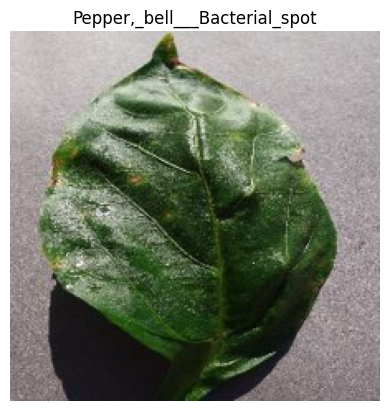

In [10]:

# Section 11: Test image preprocessing

import numpy as np
import matplotlib.pyplot as plt

IMG_SIZE = 224

# Load one image from the training data
sample = train_data[0]

# Convert the image to RGB and resize it
sample_image = sample["image"].convert("RGB").resize(
    (IMG_SIZE, IMG_SIZE)
)

# Convert the image to a NumPy array
sample_array = np.array(sample_image)

print("Image class:", sample["class_label"])
print("Image shape:", sample_array.shape)
print("Data type:", sample_array.dtype)
print("Minimum pixel value:", sample_array.min())
print("Maximum pixel value:", sample_array.max())

# Display the processed image
plt.imshow(sample_array)
plt.title(sample["class_label"])
plt.axis("off")
plt.show()


In [11]:

# Section 12: Create a batch-based image pipeline

import tensorflow as tf
import numpy as np

IMG_SIZE = 224
BATCH_SIZE = 32
AUTOTUNE = tf.data.AUTOTUNE

# Create a consistent mapping from class names to integer labels
class_names = sorted(set(plant_dataset["class_label"]))
class_to_index = {
    class_name: index
    for index, class_name in enumerate(class_names)
}

NUM_CLASSES = len(class_names)

print("Number of classes:", NUM_CLASSES)
print("Batch size:", BATCH_SIZE)
print("Image size:", IMG_SIZE, "x", IMG_SIZE)

def preprocess_image(image, label):
    image = tf.image.resize(image, (IMG_SIZE, IMG_SIZE))
    image = tf.cast(image, tf.float32)
    return image, label



def make_dataset(dataset, training=False):
    def generator():
        for example in dataset:
            image = np.array(
                example["image"].convert("RGB"),
                dtype=np.uint8
            )
            label = class_to_index[example["class_label"]]
            yield image, np.int32(label)

    output_signature = (
        tf.TensorSpec(shape=(None, None, 3), dtype=tf.uint8),
        tf.TensorSpec(shape=(), dtype=tf.int32)
    )

    data = tf.data.Dataset.from_generator(
        generator,
        output_signature=output_signature
    )

    if training:
        data = data.shuffle(1000, seed=42)

    data = data.map(
        preprocess_image,
        num_parallel_calls=AUTOTUNE
    )
    data = data.batch(BATCH_SIZE)

    # Tell TensorFlow how many batches to expect
    import math
    expected_batches = math.ceil(len(dataset) / BATCH_SIZE)
    data = data.apply(
        tf.data.experimental.assert_cardinality(expected_batches)
    )

    return data.prefetch(AUTOTUNE)

print("Pipeline functions created successfully.")


Number of classes: 38
Batch size: 32
Image size: 224 x 224
Pipeline functions created successfully.


In [12]:


# Section 13: Create the data pipelines

train_ds = make_dataset(train_data, training=True)
val_ds = make_dataset(val_data)
test_ds = make_dataset(test_records)

# Calculate the number of batches (rounding up)
import math

print("All three data pipelines have been created!")
print("Training batches:", math.ceil(len(train_data) / BATCH_SIZE))
print("Validation batches:", math.ceil(len(val_data) / BATCH_SIZE))
print("Test batches:", math.ceil(len(test_records) / BATCH_SIZE))


All three data pipelines have been created!
Training batches: 1152
Validation batches: 204
Test batches: 343


In [13]:

# Section 14: Check one batch of training images

images, labels = next(iter(train_ds))

print("Image batch shape:", images.shape)
print("Label batch shape:", labels.shape)
print("First 10 labels:", labels[:10].numpy())

Image batch shape: (32, 224, 224, 3)
Label batch shape: (32,)
First 10 labels: [30 35 25 11 25 35  3 11 30  3]


In [14]:

# Section 15: Build MobileNetV2

from tensorflow.keras.applications import MobileNetV2
from tensorflow.keras.applications.mobilenet_v2 import preprocess_input
from tensorflow.keras import layers, models

base_model = MobileNetV2(
    weights="imagenet",
    include_top=False,
    input_shape=(IMG_SIZE, IMG_SIZE, 3)
)

base_model.trainable = False

inputs = layers.Input(shape=(IMG_SIZE, IMG_SIZE, 3))
x = layers.Lambda(preprocess_input)(inputs)
x = base_model(x, training=False)
x = layers.GlobalAveragePooling2D()(x)
x = layers.Dropout(0.2)(x)
outputs = layers.Dense(NUM_CLASSES, activation="softmax")(x)

mobilenet_model = models.Model(inputs, outputs)

mobilenet_model.compile(
    optimizer="adam",
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

mobilenet_model.summary()


9406464/9406464 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step


Model: "functional"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_1 (InputLayer)      │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lambda (Lambda)                 │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ mobilenetv2_1.00_224            │ (None, 7, 7, 1280)     │     2,257,984 │
│ (Functional)                    │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 1280)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 1280)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 38)             │        48,678 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,306,662 (8.80 MB)

 Trainable params: 48,678 (190.15 KB)

 Non-trainable params: 2,257,984 (8.61 MB)

In [ ]:

# Section 16: Train MobileNetV2

from tensorflow.keras.callbacks import EarlyStopping

early_stopping = EarlyStopping(
    monitor="val_loss",
    patience=2,
    restore_best_weights=True
)

mobilenet_history = mobilenet_model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=5,
    callbacks=[early_stopping]
)


Epoch 1/5
1152/1152 ━━━━━━━━━━━━━━━━━━━━ 2330s 2s/step - accuracy: 0.9355 - loss: 0.2135 - val_accuracy: 0.9450 - val_loss: 0.1801
Epoch 2/5
1152/1152 ━━━━━━━━━━━━━━━━━━━━ 2354s 2s/step - accuracy: 0.9519 - loss: 0.1554 - val_accuracy: 0.9537 - val_loss: 0.1522
Epoch 3/5
1152/1152 ━━━━━━━━━━━━━━━━━━━━ 0s 2s/step - accuracy: 0.9591 - loss: 0.1289

In [29]:

# Section 17: Build ResNet50

from tensorflow.keras.applications import ResNet50
from tensorflow.keras.applications.resnet50 import preprocess_input
from tensorflow.keras import layers, models

base_resnet = ResNet50(
    weights="imagenet",
    include_top=False,
    input_shape=(IMG_SIZE, IMG_SIZE, 3)
)

base_resnet.trainable = False

inputs = layers.Input(shape=(IMG_SIZE, IMG_SIZE, 3))
x = layers.Lambda(preprocess_input)(inputs)
x = base_resnet(x, training=False)
x = layers.GlobalAveragePooling2D()(x)
x = layers.Dropout(0.2)(x)
outputs = layers.Dense(NUM_CLASSES, activation="softmax")(x)

resnet_model = models.Model(inputs, outputs)

resnet_model.compile(
    optimizer="adam",
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

resnet_model.summary()


94765736/94765736 ━━━━━━━━━━━━━━━━━━━━ 1s 0us/step


Model: "functional_2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_5 (InputLayer)      │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lambda_2 (Lambda)               │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ resnet50 (Functional)           │ (None, 7, 7, 2048)     │    23,587,712 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d_2      │ (None, 2048)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 2048)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 38)             │        77,862 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 23,665,574 (90.28 MB)

 Trainable params: 77,862 (304.15 KB)

 Non-trainable params: 23,587,712 (89.98 MB)

In [30]:

# Section 18: Train ResNet50

resnet_early_stopping = EarlyStopping(
    monitor="val_loss",
    patience=2,
    restore_best_weights=True
)

resnet_history = resnet_model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=5,
    callbacks=[resnet_early_stopping]
)


Epoch 1/5
1152/1152 ━━━━━━━━━━━━━━━━━━━━ 160s 125ms/step - accuracy: 0.9121 - loss: 0.3379 - val_accuracy: 0.9702 - val_loss: 0.1118
Epoch 2/5
1152/1152 ━━━━━━━━━━━━━━━━━━━━ 133s 114ms/step - accuracy: 0.9718 - loss: 0.0994 - val_accuracy: 0.9791 - val_loss: 0.0759
Epoch 3/5
1152/1152 ━━━━━━━━━━━━━━━━━━━━ 132s 113ms/step - accuracy: 0.9782 - loss: 0.0709 - val_accuracy: 0.9796 - val_loss: 0.0667
Epoch 4/5
1152/1152 ━━━━━━━━━━━━━━━━━━━━ 133s 114ms/step - accuracy: 0.9833 - loss: 0.0534 - val_accuracy: 0.9799 - val_loss: 0.0674
Epoch 5/5
1152/1152 ━━━━━━━━━━━━━━━━━━━━ 141s 114ms/step - accuracy: 0.9845 - loss: 0.0476 - val_accuracy: 0.9828 - val_loss: 0.0498


In [31]:

# Section 19: Evaluate both models on the test set

mobilenet_test_loss, mobilenet_test_accuracy = mobilenet_model.evaluate(
    test_ds, verbose=1
)

resnet_test_loss, resnet_test_accuracy = resnet_model.evaluate(
    test_ds, verbose=1
)

print("\nTest Results")
print(f"MobileNetV2 accuracy: {mobilenet_test_accuracy:.4f}")
print(f"MobileNetV2 loss: {mobilenet_test_loss:.4f}")
print(f"ResNet50 accuracy: {resnet_test_accuracy:.4f}")
print(f"ResNet50 loss: {resnet_test_loss:.4f}")


343/343 ━━━━━━━━━━━━━━━━━━━━ 24s 70ms/step - accuracy: 0.9509 - loss: 0.1558
343/343 ━━━━━━━━━━━━━━━━━━━━ 36s 104ms/step - accuracy: 0.9790 - loss: 0.0713

Test Results
MobileNetV2 accuracy: 0.9509
MobileNetV2 loss: 0.1558
ResNet50 accuracy: 0.9790
ResNet50 loss: 0.0713


In [32]:

# Section 20: Compare precision, recall, and F1-score

from sklearn.metrics import classification_report
import numpy as np

y_true = np.concatenate([
    labels.numpy() for images, labels in test_ds
])

mobilenet_predictions = np.argmax(
    mobilenet_model.predict(test_ds, verbose=1), axis=1
)

resnet_predictions = np.argmax(
    resnet_model.predict(test_ds, verbose=1), axis=1
)

print("MobileNetV2 classification report:")
print(classification_report(
    y_true,
    mobilenet_predictions,
    target_names=class_names,
    digits=3,
    zero_division=0
))

print("\nResNet50 classification report:")
print(classification_report(
    y_true,
    resnet_predictions,
    target_names=class_names,
    digits=3,
    zero_division=0
))


343/343 ━━━━━━━━━━━━━━━━━━━━ 30s 76ms/step
343/343 ━━━━━━━━━━━━━━━━━━━━ 41s 109ms/step
MobileNetV2 classification report:
                                                    precision    recall  f1-score   support

                                Apple___Apple_scab      0.897     0.919     0.908       123
                                 Apple___Black_rot      0.983     0.960     0.971       124
                          Apple___Cedar_apple_rust      0.963     0.945     0.954        55
                                   Apple___healthy      0.981     0.981     0.981       324
                               Blueberry___healthy      0.972     1.000     0.986       278
          Cherry_(including_sour)___Powdery_mildew      0.996     0.992     0.994       252
                 Cherry_(including_sour)___healthy      0.983     0.994     0.989       179
Corn_(maize)___Cercospora_leaf_spot Gray_leaf_spot      0.865     0.748     0.802       103
                       Corn_(maize)___Common_rust

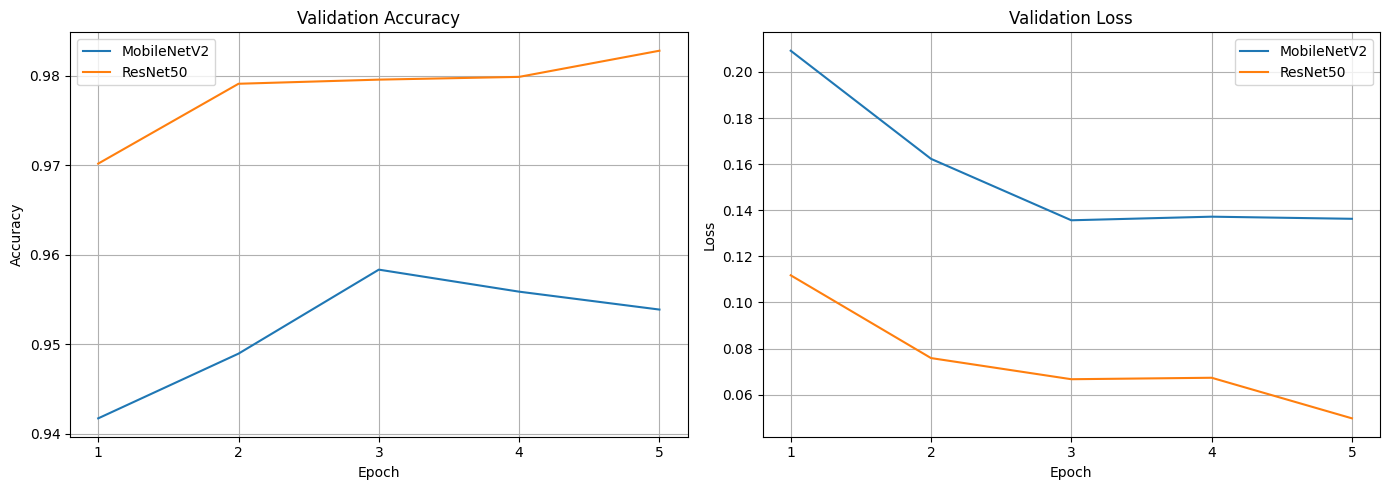

In [33]:

# Section 21: Plot training and validation curves

import matplotlib.pyplot as plt

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

axes[0].plot(mobilenet_history.history["val_accuracy"], label="MobileNetV2")
axes[0].plot(resnet_history.history["val_accuracy"], label="ResNet50")
axes[0].set_title("Validation Accuracy")
axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("Accuracy")
axes[0].set_xticks(range(5), range(1, 6))
axes[0].legend()
axes[0].grid(True)

axes[1].plot(mobilenet_history.history["val_loss"], label="MobileNetV2")
axes[1].plot(resnet_history.history["val_loss"], label="ResNet50")
axes[1].set_title("Validation Loss")
axes[1].set_xlabel("Epoch")
axes[1].set_ylabel("Loss")
axes[1].set_xticks(range(5), range(1, 6))
axes[1].legend()
axes[1].grid(True)

plt.tight_layout()
plt.show()


In [34]:

# Section 22: Save the trained models

mobilenet_model.save("mobilenetv2_plant_disease.keras")
resnet_model.save("resnet50_plant_disease.keras")

print("Both models saved successfully!")


Both models saved successfully!


In [35]:

# Section 23: Summarise model performance

import pandas as pd

results = pd.DataFrame({
    "Model": ["MobileNetV2", "ResNet50"],
    "Test Accuracy": [
        mobilenet_test_accuracy,
        resnet_test_accuracy
    ],
    "Test Loss": [
        mobilenet_test_loss,
        resnet_test_loss
    ],
    "Macro F1-score": [0.939, 0.970],
    "Weighted F1-score": [0.951, 0.979]
})

results[["Test Accuracy", "Macro F1-score", "Weighted F1-score"]] = (
    results[["Test Accuracy", "Macro F1-score", "Weighted F1-score"]] * 100
).round(2)

results["Test Loss"] = results["Test Loss"].round(4)

print(results.to_string(index=False))


      Model  Test Accuracy  Test Loss  Macro F1-score  Weighted F1-score
MobileNetV2          95.09     0.1558            93.9               95.1
   ResNet50          97.90     0.0713            97.0               97.9


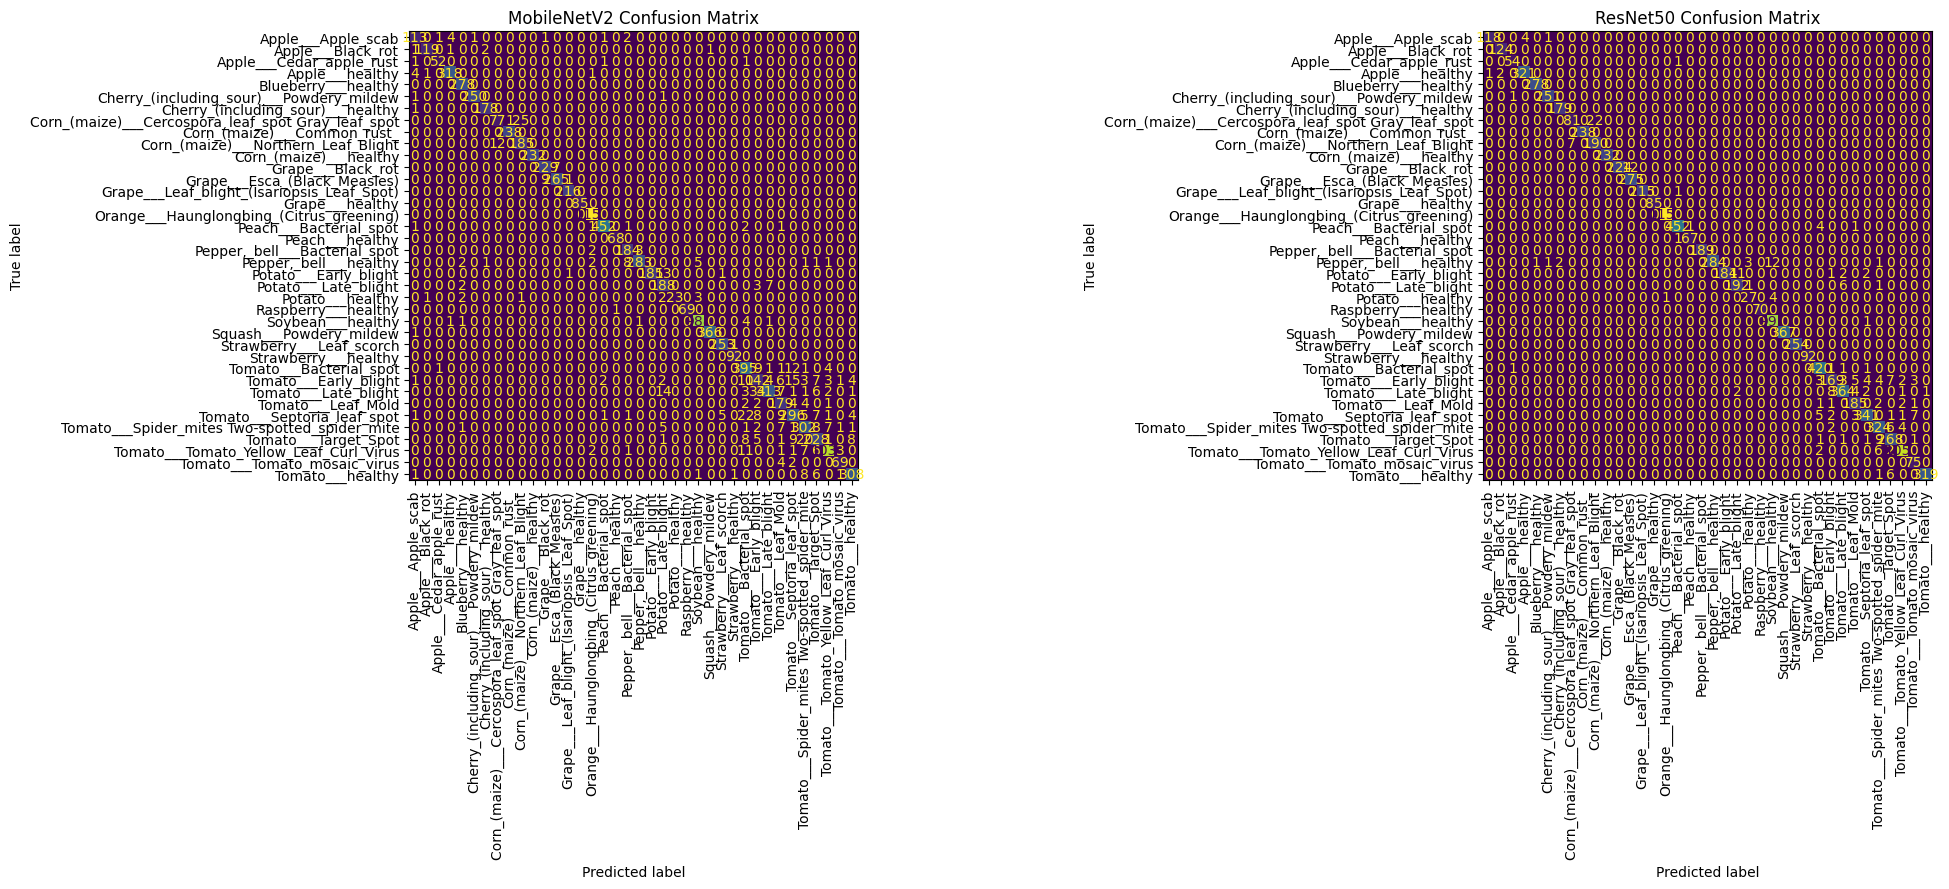

In [36]:

# Section 24: Create confusion matrices

from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt

mobilenet_cm = confusion_matrix(y_true, mobilenet_predictions)
resnet_cm = confusion_matrix(y_true, resnet_predictions)

fig, axes = plt.subplots(1, 2, figsize=(22, 9))

ConfusionMatrixDisplay(
    confusion_matrix=mobilenet_cm,
    display_labels=class_names
).plot(ax=axes[0], xticks_rotation=90, colorbar=False, values_format="d")

axes[0].set_title("MobileNetV2 Confusion Matrix")

ConfusionMatrixDisplay(
    confusion_matrix=resnet_cm,
    display_labels=class_names
).plot(ax=axes[1], xticks_rotation=90, colorbar=False, values_format="d")

axes[1].set_title("ResNet50 Confusion Matrix")

plt.tight_layout()
plt.show()


In [1]:
!pip install -q scikit-learn matplotlib pandas